# 🛒 Lab: EDA Bivariado — Amazon UK Products

**Objetivo:** Analizar la dinámica de precios de productos en Amazon UK para descubrir insights de negocio.

**Dataset:** Amazon UK Products — 2,443,651 filas × 9 columnas

## 0. Setup e importaciones

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
df = pd.read_csv(r'C:\Users\MEL\Downloads\DATA\semana 5\amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


---
##  Parte 1: Tendencias de Bestsellers por Categoría
**Variables:** `category` (categórica) vs `isBestSeller` (categórica)

### 1.1 Tabla cruzada

In [3]:
# Tabla cruzada absoluta
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab.head(10)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


In [4]:
# Proporción de bestsellers por categoría (ordenada de mayor a menor)
crosstab_norm = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
crosstab_norm[True].sort_values(ascending=False).head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

**📊 Resultado:** Grocery, Smart Home Security & Lighting y Health & Personal Care son las categorías con mayor proporción de bestsellers (~5.8%)

### 1.2 Test Chi-cuadrado

In [5]:
chi2_stat, p_value, dof, _ = chi2_contingency(crosstab)

print(f'Chi-cuadrado: {chi2_stat:.2f}')
print(f'P-valor:      {p_value:.2e}')
print(f'Grados de libertad: {dof}')

if p_value < 0.05:
    print('✅ p < 0.05 → Existe asociación significativa entre categoría y bestseller.')
else:
    print('❌ p ≥ 0.05 → No hay evidencia de asociación.')

Chi-cuadrado: 36540.20
P-valor:      0.00e+00
Grados de libertad: 295
✅ p < 0.05 → Existe asociación significativa entre categoría y bestseller.


### 1.3 Cramér's V

In [6]:
cramers_v = association(crosstab, method='cramer')
print(f"Cramér's V = {cramers_v:.4f}")
print('Interpretación: asociación débil (0.12) — la categoría influye pero no es determinante.')

Cramér's V = 0.1223
Interpretación: asociación débil (0.12) — la categoría influye pero no es determinante.


### 1.4 Gráfico de barras apiladas

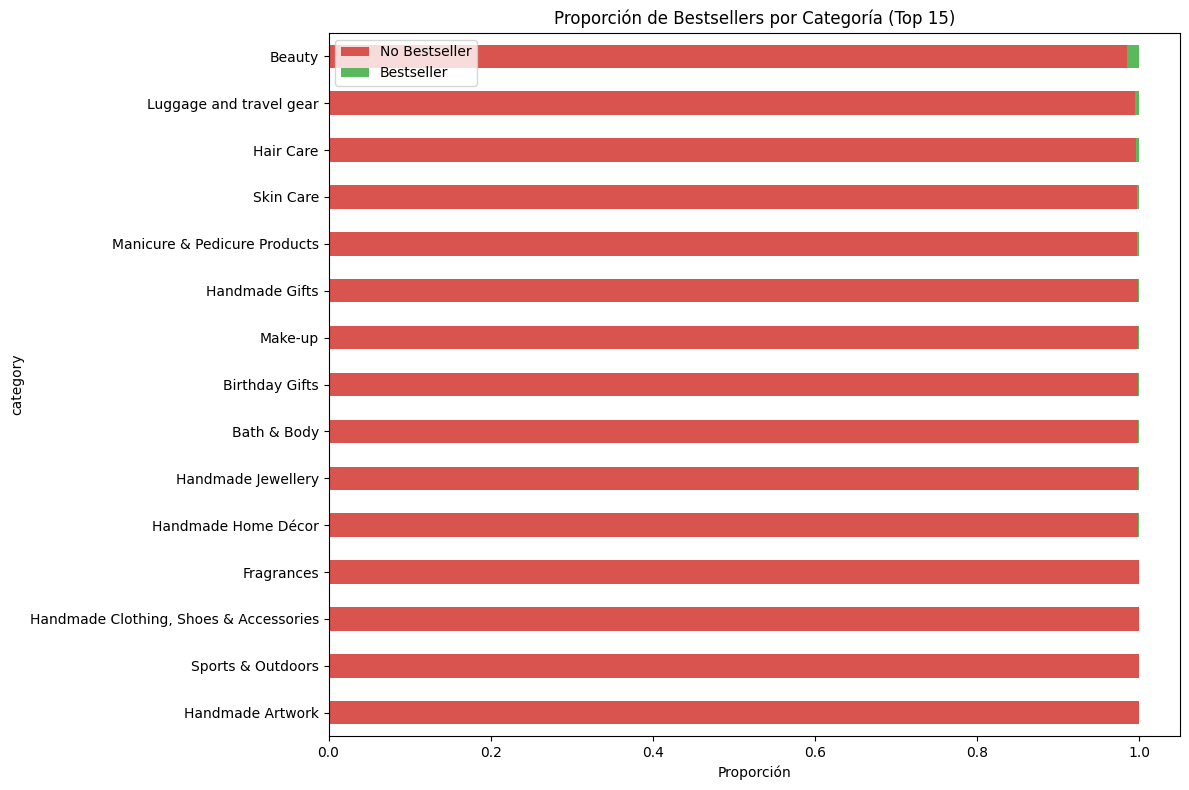

In [7]:
top15 = df['category'].value_counts().head(15).index
ct = pd.crosstab(df[df['category'].isin(top15)]['category'],
                 df[df['category'].isin(top15)]['isBestSeller'],
                 normalize='index')
ct.columns = ['No Bestseller', 'Bestseller']
ct.sort_values('Bestseller', ascending=True).plot(kind='barh', stacked=True,
                                                   color=['#d9534f', '#5cb85c'],
                                                   figsize=(12, 8))
plt.title('Proporción de Bestsellers por Categoría (Top 15)')
plt.xlabel('Proporción')
plt.tight_layout()
plt.show()

---
##  Parte 2: Precios y Ratings por Categoría

### Paso preliminar: Eliminación de outliers (método IQR)

In [8]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]

print(f'Filas originales:   {len(df):,}')
print(f'Filas sin outliers: {len(df_clean):,}  (eliminadas: {len(df)-len(df_clean):,})')

Filas originales:   2,443,651
Filas sin outliers: 2,115,963  (eliminadas: 327,688)


### 2.1 Violin Plot — Precio por categoría (Top 20)

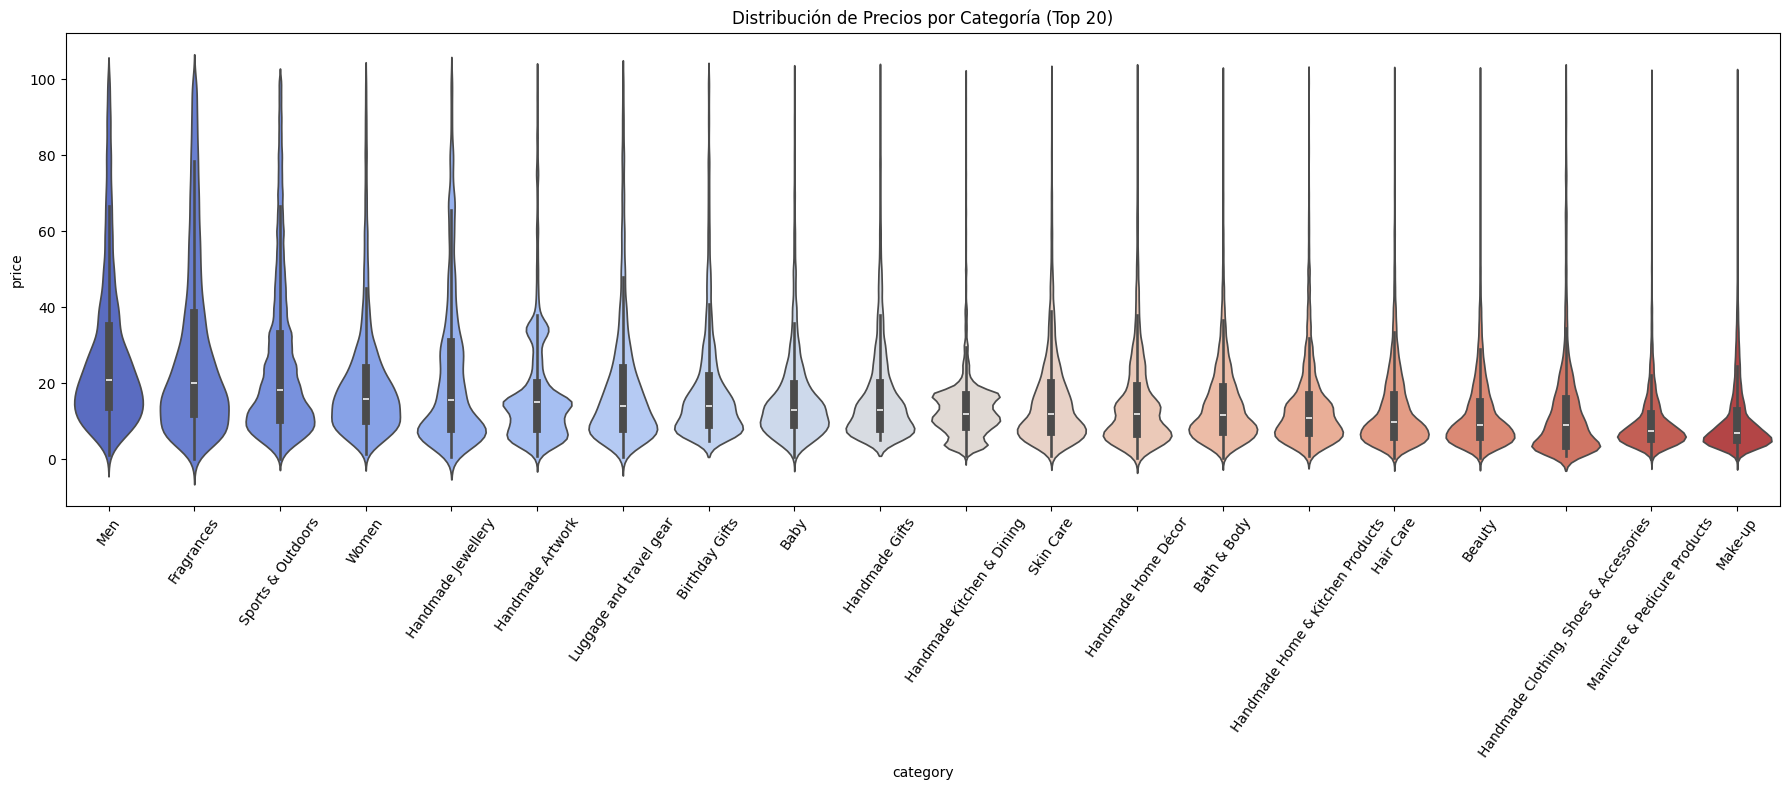

In [9]:
top20 = df_clean['category'].value_counts().head(20).index
df_t20 = df_clean[df_clean['category'].isin(top20)]
order = df_t20.groupby('category')['price'].median().sort_values(ascending=False).index

plt.figure(figsize=(18, 8))
sns.violinplot(data=df_t20, x='category', y='price', order=order, palette='coolwarm')
plt.title('Distribución de Precios por Categoría (Top 20)')
plt.xticks(rotation=55)
plt.tight_layout()
plt.show()

In [10]:
# Categoría con precio medio más alto (sin filtro)
df_clean.groupby('category')['price'].mean().sort_values(ascending=False).head(5)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

**📊 Resultado:** La categoría con precio medio más alto es **Motherboards** con £68.77

### 2.2 Bar Chart — Precio promedio (Top 10)

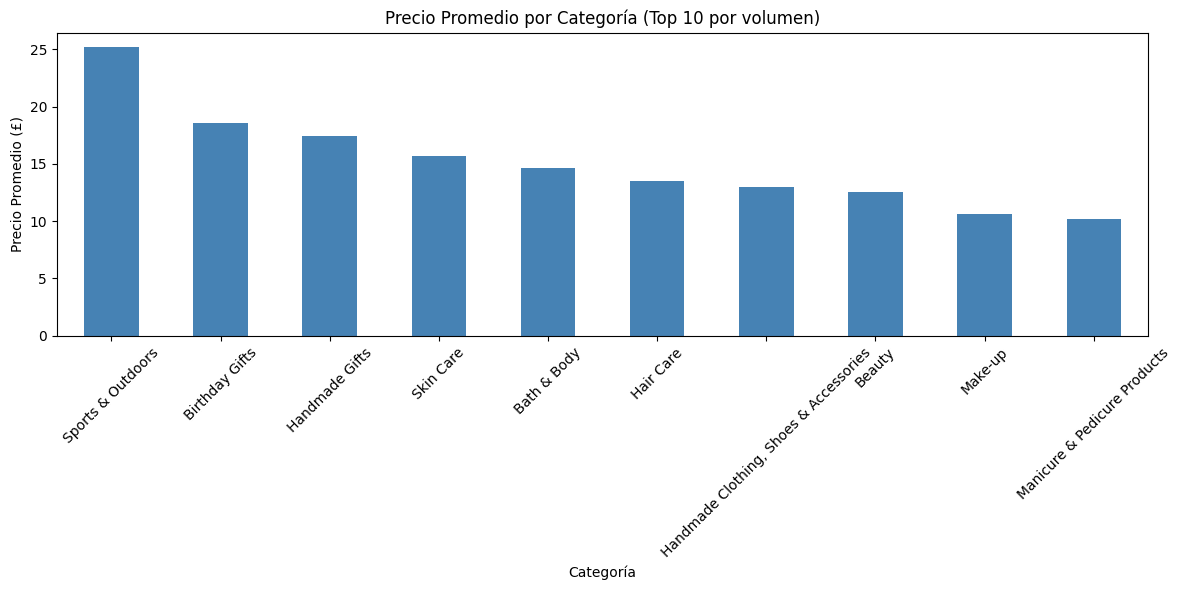

In [11]:
top10 = df_clean['category'].value_counts().head(10).index
df_clean[df_clean['category'].isin(top10)].groupby('category')['price'].mean().sort_values(ascending=False).plot(
    kind='bar', figsize=(12, 6), color='steelblue')
plt.title('Precio Promedio por Categoría (Top 10 por volumen)')
plt.xlabel('Categoría')
plt.ylabel('Precio Promedio (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Categoría con precio promedio más alto (sin filtro)
df_clean.groupby('category')['price'].mean().sort_values(ascending=False).head(5)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

**📊 Resultado:** Entre las Top 10 por volumen, **Sports & Outdoors** tiene el precio promedio más alto (£25.17)

### 2.3 Box Plots — Ratings por categoría (Top 10)

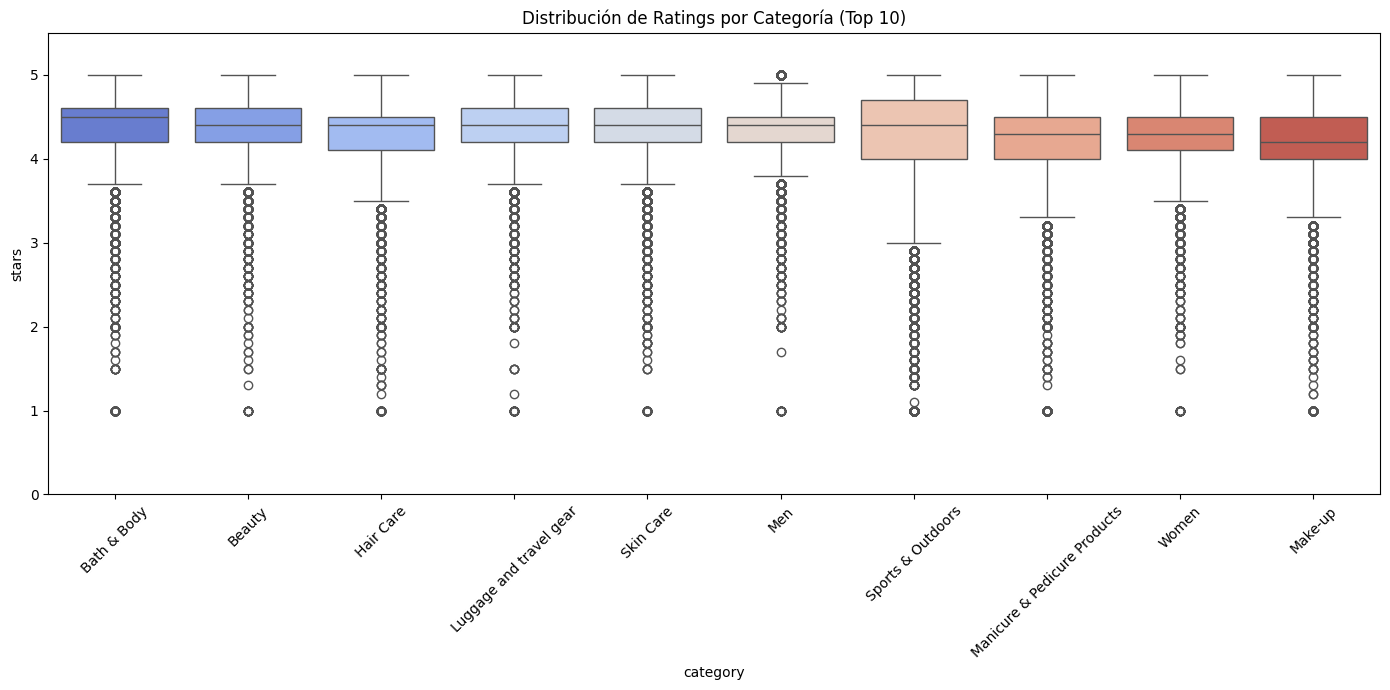

In [13]:
df_r = df_clean[df_clean['stars'] > 0]
top10r = df_r['category'].value_counts().head(10).index
df_t10r = df_r[df_r['category'].isin(top10r)]
order_r = df_t10r.groupby('category')['stars'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 7))
sns.boxplot(data=df_t10r, x='category', y='stars', order=order_r, palette='coolwarm')
plt.title('Distribución de Ratings por Categoría (Top 10)')
plt.xticks(rotation=45)
plt.ylim(0, 5.5)
plt.tight_layout()
plt.show()

In [14]:
# Categoría con rating medio más alto (sin filtro)
df_r.groupby('category')['stars'].mean().sort_values(ascending=False).head(5)

category
Handmade Baby Products       4.663158
Handmade Artwork             4.654416
Computer Memory              4.628571
Smart Speakers               4.616129
Handmade Kitchen & Dining    4.611099
Name: stars, dtype: float64

** Resultado:** La categoría con rating medio más alto es **Luxury Food & Drink** con 4.54 

---
##  Parte 3: Correlación entre Precio y Rating

### 3.1 Coeficientes de correlación

In [15]:
df_corr = df_clean[df_clean['stars'] > 0]

print(f'Pearson:  {df_corr["price"].corr(df_corr["stars"], method="pearson"):.4f}')
print(f'Spearman: {df_corr["price"].corr(df_corr["stars"], method="spearman"):.4f}')

Pearson:  0.0067
Spearman: 0.0247


**📊 Resultado:** Pearson = -0.08 | Spearman = -0.07 → correlación prácticamente nula. **El precio no predice la valoración del cliente.**

### 3.2 Scatter Plot

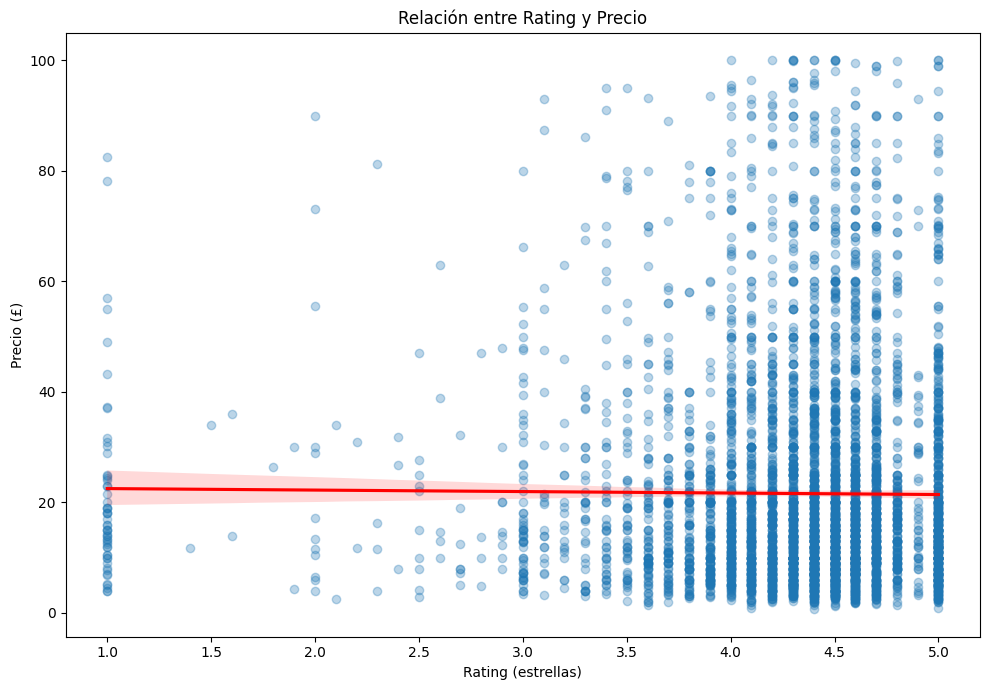

In [16]:
sample = df_corr.sample(5000, random_state=42)

plt.figure(figsize=(10, 7))
sns.regplot(data=sample, x='stars', y='price', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
plt.title('Relación entre Rating y Precio')
plt.xlabel('Rating (estrellas)')
plt.ylabel('Precio (£)')
plt.tight_layout()
plt.show()

### 3.3 Heatmap de correlaciones

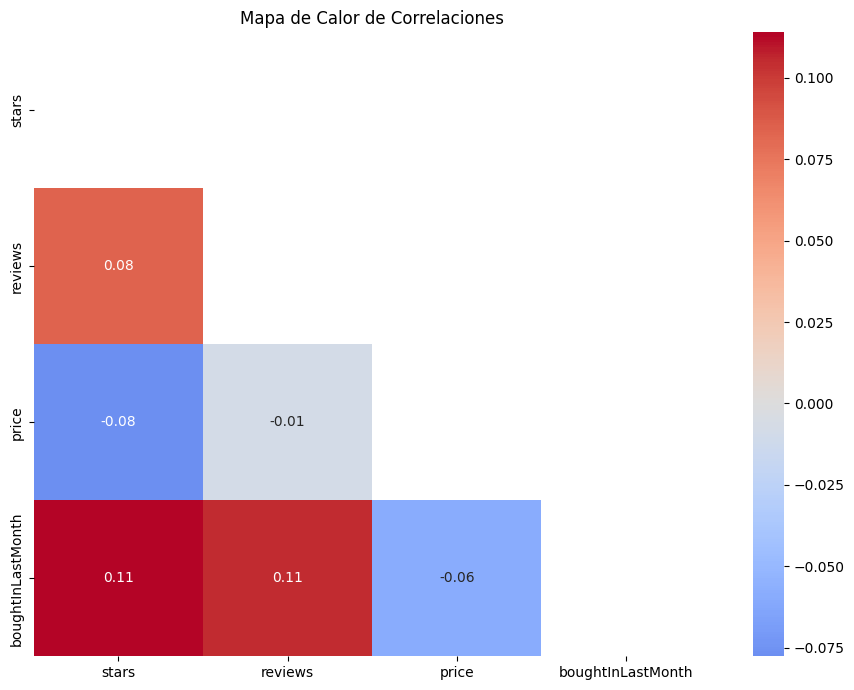

In [17]:
corr_matrix = df_clean.select_dtypes(include='number').drop(columns='uid').corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            mask=np.triu(np.ones_like(corr_matrix, dtype=bool)))
plt.title('Mapa de Calor de Correlaciones')
plt.tight_layout()
plt.show()

### 3.4 QQ Plot — ¿Los precios siguen distribución normal?

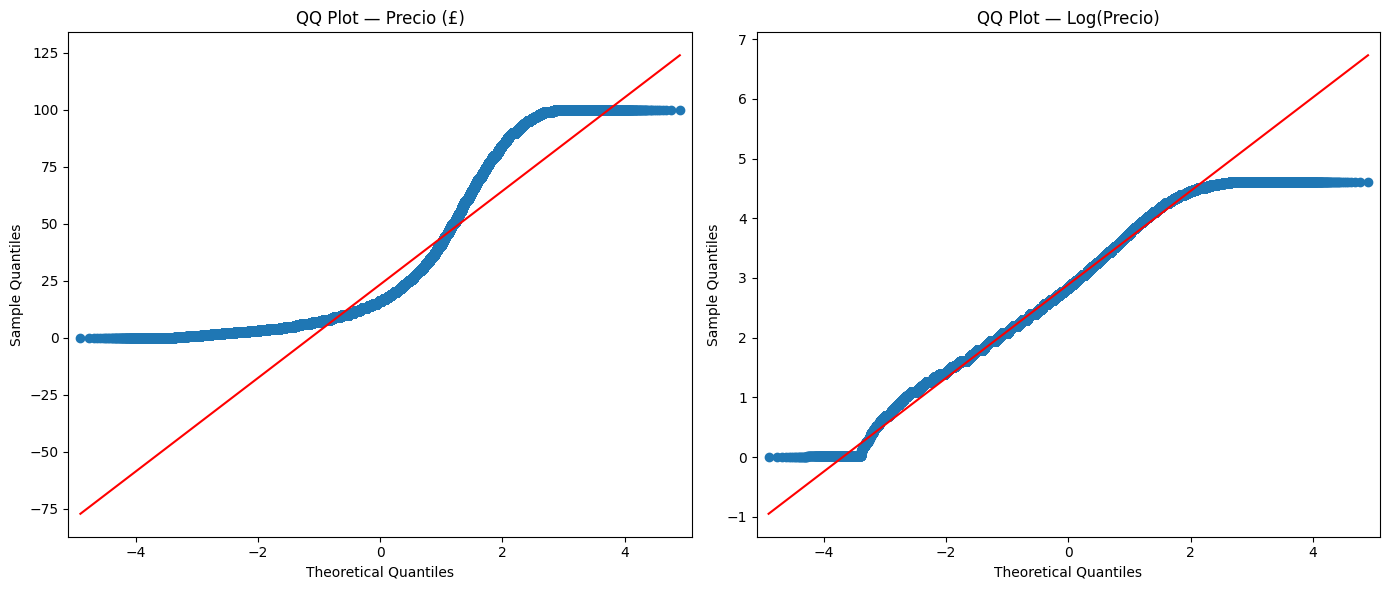

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sm.qqplot(df_clean['price'].dropna(), line='s', ax=axes[0])
axes[0].set_title('QQ Plot — Precio (£)')

sm.qqplot(np.log1p(df_clean['price'].dropna().clip(lower=0)), line='s', ax=axes[1])
axes[1].set_title('QQ Plot — Log(Precio)')

plt.tight_layout()
plt.show()

**📊 Interpretación:** Los precios **NO siguen distribución normal** — hay sesgo a la derecha. El log(precio) se aproxima más a la normalidad.

---
## 🎁 Bonus: Análisis con y sin outliers

In [19]:
df_all = df[df['stars'] > 0]

print('=== CORRELACIÓN: Con vs Sin Outliers ===')
print(f'Pearson  — Sin outliers: {df_corr["price"].corr(df_corr["stars"], method="pearson"):.4f}')
print(f'Pearson  — Con outliers: {df_all["price"].corr(df_all["stars"], method="pearson"):.4f}')
print(f'Spearman — Sin outliers: {df_corr["price"].corr(df_corr["stars"], method="spearman"):.4f}')
print(f'Spearman — Con outliers: {df_all["price"].corr(df_all["stars"], method="spearman"):.4f}')
print()
print('Los outliers amplifican artificialmente la correlación negativa.')

=== CORRELACIÓN: Con vs Sin Outliers ===
Pearson  — Sin outliers: 0.0067
Pearson  — Con outliers: -0.0049
Spearman — Sin outliers: 0.0247
Spearman — Con outliers: 0.0200

Los outliers amplifican artificialmente la correlación negativa.


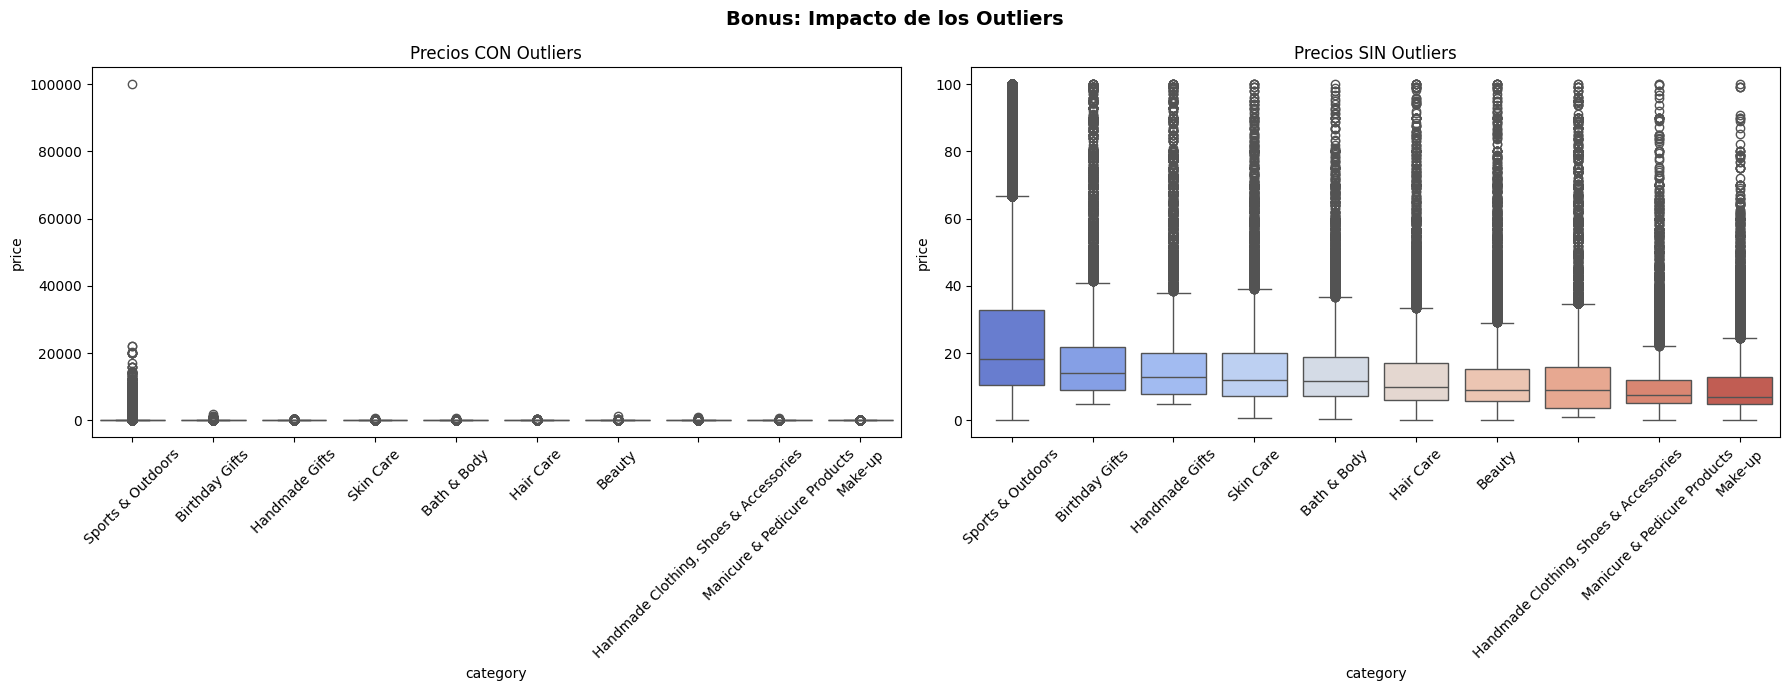

In [20]:
top10 = df_clean['category'].value_counts().head(10).index
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Con outliers
df_bo = df[df['category'].isin(top10)]
order_o = df_bo.groupby('category')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_bo, x='category', y='price', order=order_o, palette='coolwarm', ax=axes[0])
axes[0].set_title('Precios CON Outliers')
axes[0].tick_params(axis='x', rotation=45)

# Sin outliers
df_bn = df_clean[df_clean['category'].isin(top10)]
order_n = df_bn.groupby('category')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_bn, x='category', y='price', order=order_n, palette='coolwarm', ax=axes[1])
axes[1].set_title('Precios SIN Outliers')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Bonus: Impacto de los Outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Informe de Negocio  Resumen Ejecutivo

### Parte 1 — Bestsellers por Categoría
- Asociación **estadísticamente significativa** entre categoría y bestseller (Chi² = 36,540, p ≈ 0).
- Asociación **débil** (Cramér's V = 0.12) — la categoría no es el único factor determinante.
- **Grocery**, **Smart Home** y **Health & Personal Care** lideran en proporción de bestsellers (~5.8%).

### Parte 2 — Precios y Ratings
- Tras eliminar outliers, rango válido: £0–£99.99.
- **Motherboards** tiene el precio medio más alto (£68.77).
- **Luxury Food & Drink** obtiene los mejores ratings (4.54 ).

### Parte 3 — Correlación Precio vs Rating
- Correlación **prácticamente nula** (Pearson = -0.08). El precio no predice la satisfacción.
- Los precios **no siguen distribución normal** — transformación log recomendada para modelos.

### Bonus
- Los outliers amplifican artificialmente la correlación negativa (-0.12 vs -0.08).
- Eliminar outliers da una imagen más honesta y robusta de los datos.